# Fase 2: exploração e identificação

Decide, para cada UF, a transformação, o número de diferenças e se há termo sazonal.
Essas decisões definem os modelos da fase 3.

Entrada: `data/processed/aneel_serie_mensal_uf.parquet` (gerado por `python src/main.py`).
Referência: FPP3, §2.8, §3.1, §3.6, §4.3 e §9.1. Os comentários abaixo foram escritos com o retrato da ANEEL de out/2026.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf, zivot_andrews

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
warnings.simplefilter("ignore", InterpolationWarning)  # o p-valor do KPSS é truncado em [0,01; 0,10]
pd.set_option("display.precision", 3)

RES = ROOT / "resultados"
ANTES_LEI = "2021-12"
TODAS = UFS + ["SE"]

serie = pd.read_parquet(ROOT / "data" / "processed" / "aneel_serie_mensal_uf.parquet")
y = {uf: g.set_index("mes")["log_mw"].asfreq("MS") for uf, g in serie.groupby("uf", observed=True)}
print(f"{serie['mes'].min():%Y-%m} a {serie['mes'].max():%Y-%m}, {len(y['SE'])} meses por UF")

2016-01 a 2026-06, 126 meses por UF


## 1. Transformação

A série é a potência adicionada por mês (MW). Ela cresce duas ordens de grandeza entre 2016 e 2022, e a
variação mês a mês acompanha o nível ([gráfico](../resultados/aneel_serie_log_uf.png)). O log estabiliza a
variância e transforma crescimento percentual em diferença constante (§3.1).
Todo mês tem potência positiva, então o log é definido sem deslocamento.

## 2. Decomposição STL

STL sobre o log, com período 12, ajuste robusto e as janelas padrão do FPP3 para dados mensais (§3.6):
sazonal 11 e tendência 21.

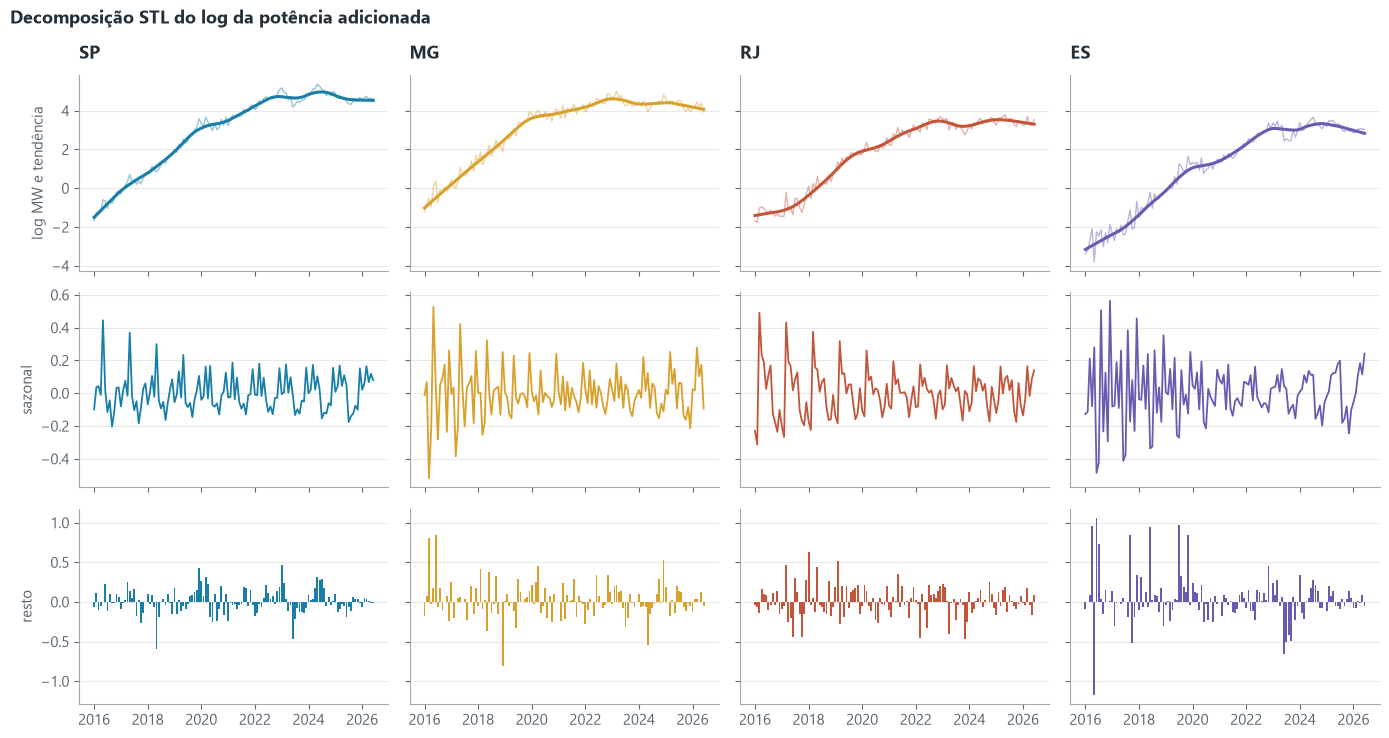

In [2]:
stl = {uf: STL(y[uf], period=12, seasonal=11, trend=21, robust=True).fit() for uf in TODAS}

fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey="row")
for j, uf in enumerate(UFS):
    r, cor = stl[uf], CORES_UF[uf]
    axes[0, j].plot(y[uf].index, y[uf], color=cor, lw=1, alpha=0.45)
    axes[0, j].plot(r.trend.index, r.trend, color=cor, lw=2.2)
    axes[1, j].plot(r.seasonal.index, r.seasonal, color=cor, lw=1.3)
    axes[2, j].bar(r.resid.index, r.resid, width=25, color=cor)
    axes[0, j].set_title(uf)
for ax, nome in zip(axes[:, 0], ["log MW e tendência", "sazonal", "resto"]):
    ax.set_ylabel(nome)
for ax in axes[2]:
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Decomposição STL do log da potência adicionada", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "ident_stl_uf.png")

Força da tendência e da sazonalidade (§4.3):

$$F_T = \max\left(0,\ 1 - \frac{\mathrm{Var}(R_t)}{\mathrm{Var}(T_t + R_t)}\right), \qquad
F_S = \max\left(0,\ 1 - \frac{\mathrm{Var}(R_t)}{\mathrm{Var}(S_t + R_t)}\right)$$

O FPP3 usa $F_S > 0{,}64$ como critério para tomar uma diferença sazonal.

In [3]:
def forcas(r):
    ft = max(0, 1 - r.resid.var() / (r.trend + r.resid).var())
    fs = max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
    return ft, fs

tab_forca = pd.DataFrame({uf: forcas(stl[uf]) for uf in TODAS},
                         index=["força da tendência", "força sazonal"]).T
tab_forca["diferença sazonal (F_S > 0,64)"] = np.where(tab_forca["força sazonal"] > 0.64, "sim", "não")
tab_forca

,força da tendência,força sazonal,"diferença sazonal (F_S > 0,64)"
SP,0.994,0.324,não
MG,0.983,0.184,não
RJ,0.989,0.331,não
ES,0.980,0.009,não
SE,0.994,0.253,não


,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
SP,-3.2,1.2,14.3,-0.2,19.4,-1.1,-11.5,-7.6,-14.6,-5.3,-1.5,11.8
MG,1.1,-1.5,-1.1,-8.2,21.3,-4.9,-4.2,1.8,-3.3,-4.8,-9.3,11.9
RJ,-13.4,-13.7,26.5,8.2,11.5,4.1,3.9,6.6,-7.5,-16.3,-7.3,-1.3
ES,-0.7,-0.2,13.7,-2.0,18.6,-11.0,-14.6,7.2,-10.7,-1.7,-16.9,16.9


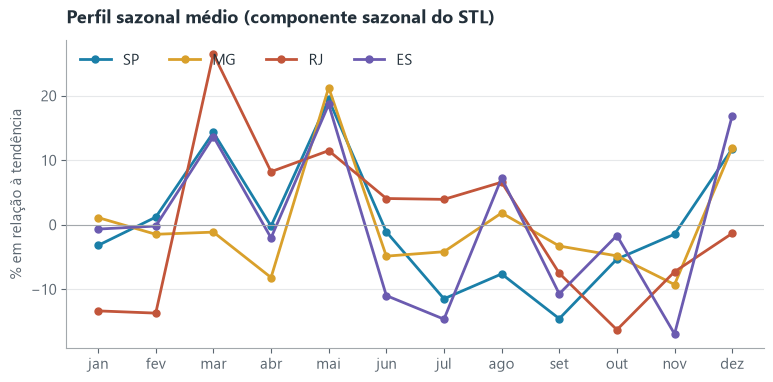

In [4]:
# perfil sazonal médio: componente sazonal por mês do ano, em % (diferença de log ≈ variação %)
perfil = pd.DataFrame({uf: stl[uf].seasonal.groupby(stl[uf].seasonal.index.month).mean() * 100
                       for uf in UFS})
perfil.index = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(figsize=(9, 4))
for uf in UFS:
    ax.plot(perfil.index, perfil[uf], color=CORES_UF[uf], lw=2, marker="o", ms=5, label=uf)
ax.axhline(0, color=estilo.NEUTRO, lw=0.8)
ax.set_ylabel("% em relação à tendência")
ax.set_title("Perfil sazonal médio (componente sazonal do STL)")
ax.legend(ncol=4, loc="upper left")
fig.savefig(RES / "ident_perfil_sazonal.png")
perfil.round(1).T

**Leitura.**
- A tendência domina ($F_T \approx 0{,}98$ em todas as UFs).
- A sazonalidade é fraca: $F_S$ fica no máximo em 0,33, bem abaixo de 0,64, em todas as UFs, então **não há diferença sazonal** ($D = 0$).
- No perfil sazonal, dois meses se repetem: maio fica acima da tendência nas quatro UFs (+12 a +21%), e dezembro em SP, MG e ES (+12 a +17%). O resto muda de UF para UF. Se algum efeito sazonal entrar no modelo, será como termo sazonal AR/MA ou como dummy de mês, nunca como diferença.
- O resto do STL é maior em 2016–2018, quando as séries tinham poucas usinas por mês, sobretudo em RJ e ES.

## 3. ACF e PACF da série diferenciada

ACF e PACF de $\Delta \log y_t$ até 24 meses (§2.8, §9.5). A faixa cinza é $\pm 1{,}96/\sqrt{T}$.

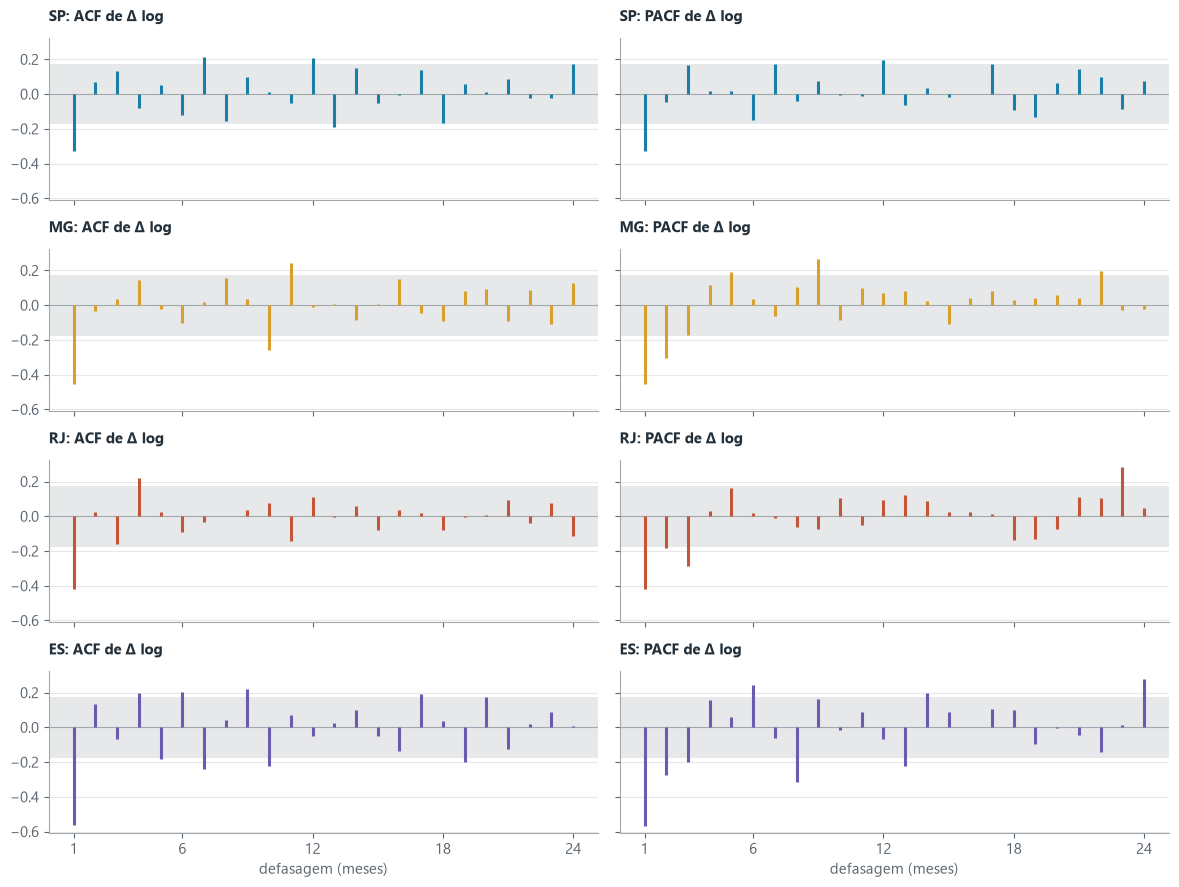

In [5]:
NL = 24
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True, sharey=True)
for i, uf in enumerate(UFS):
    dy = y[uf].diff().dropna()
    banda = 1.96 / np.sqrt(len(dy))
    for j, (func, nome) in enumerate([(acf, "ACF"), (pacf, "PACF")]):
        ax = axes[i, j]
        ax.axhspan(-banda, banda, color=estilo.GRADE, lw=0)
        ax.axhline(0, color=estilo.NEUTRO, lw=0.8)
        ax.vlines(range(1, NL + 1), 0, func(dy, nlags=NL)[1:], color=CORES_UF[uf], lw=2.2)
        ax.set_title(f"{uf}: {nome} de Δ log", fontsize=11)
for ax in axes[-1]:
    ax.set_xticks([1, 6, 12, 18, 24])
    ax.set_xlabel("defasagem (meses)")
fig.tight_layout()
fig.savefig(RES / "ident_acf_pacf_uf.png")

In [6]:
tab_acf = pd.DataFrame({uf: acf(y[uf].diff().dropna(), nlags=12)[[1, 2, 12]] for uf in TODAS},
                       index=["ACF lag 1", "ACF lag 2", "ACF lag 12"]).T
tab_acf["banda ±1,96/√T"] = 1.96 / np.sqrt(len(y["SE"]) - 1)
tab_acf

,ACF lag 1,ACF lag 2,ACF lag 12,"banda ±1,96/√T"
SP,-0.327,0.068,0.206,0.175
MG,-0.451,-0.035,-0.012,0.175
RJ,-0.417,0.024,0.111,0.175
ES,-0.562,0.133,-0.052,0.175
SE,-0.424,0.078,0.075,0.175


**Leitura.**
- Em todas as UFs, a ACF de $\Delta \log y_t$ tem um pico negativo no lag 1 (entre −0,3 e −0,6) e corta depois dele.
- Em MG, RJ e ES, a PACF decai nos lags 1 a 3. É o padrão de um **MA(1)** na diferença, ou seja, um **ARIMA(0,1,1)**.
- Em SP, ACF e PACF cortam ambas no lag 1, então ARIMA(1,1,0) e ARIMA(0,1,1) são igualmente candidatos.
- O ARIMA(0,1,1) equivale a suavização exponencial simples (§9.10): o nível segue um passeio aleatório e o ruído mensal se sobrepõe a ele.
- O lag 12 passa da banda só em SP. É o candidato a termo sazonal (SAR(1) ou SMA(1) com período 12), a ser testado por AICc na fase 3.

## 4. Raiz unitária e diferenciação

Seguindo o FPP3 (§9.1), o teste principal é o **KPSS**, cuja hipótese nula é de estacionariedade.
O ADF, com nula de raiz unitária, entra como contraprova. O `ndiffs` reproduz o `unitroot_ndiffs` do livro:
diferencia enquanto o KPSS rejeitar a 5%.
O p-valor do KPSS do statsmodels é truncado: 0,010 quer dizer ≤ 0,01, e 0,100 quer dizer ≥ 0,10.

Os testes rodam em duas amostras: a série inteira e só o trecho anterior à lei (até dez/2021).
Uma quebra estrutural faz esses testes enxergarem raiz unitária onde não há (Perron, 1989). Se as duas amostras
discordarem, a suspeita recai sobre a quebra.

In [7]:
def p_kpss(x, reg="c"):
    return kpss(x.dropna(), regression=reg, nlags="auto", result_object=False)[1]

def p_adf(x, reg="c"):
    return adfuller(x.dropna(), regression=reg, autolag="AIC", result_object=False)[1]

def ndiffs(x, alpha=0.05):
    """Como o unitroot_ndiffs do FPP3: diferencia enquanto o KPSS rejeitar estacionariedade."""
    d = 0
    while d < 2 and p_kpss(x) < alpha:
        x, d = x.diff(), d + 1
    return d

linhas = []
for uf in TODAS:
    for amostra, x in [("2016–2026", y[uf]), ("2016–2021", y[uf][:ANTES_LEI])]:
        linhas.append({"UF": uf, "amostra": amostra,
                       "KPSS log p": p_kpss(x, "ct"), "ADF log p": p_adf(x, "ct"),
                       "KPSS Δlog p": p_kpss(x.diff()), "ADF Δlog p": p_adf(x.diff()),
                       "ndiffs": ndiffs(x)})
tab_raiz = pd.DataFrame(linhas).set_index(["UF", "amostra"])
tab_raiz

KPSS log p  ADF log p  KPSS Δlog p  ADF Δlog p  ndiffs
UF amostra                                                          
SP 2016–2026       0.010      0.954        0.010   1.357e-28       2
   2016–2021       0.011      0.409        0.100   1.099e-24       1
MG 2016–2026       0.010      0.893        0.086   1.455e-01       1
   2016–2021       0.010      0.954        0.089   5.067e-01       1
RJ 2016–2026       0.010      0.991        0.077   1.314e-05       1
   2016–2021       0.049      0.417        0.100   3.126e-14       1
ES 2016–2026       0.010      0.995        0.051   1.082e-01       1
   2016–2021       0.010      0.637        0.100   4.732e-02       1
SE 2016–2026       0.010      0.983        0.010   1.045e-04       2
   2016–2021       0.010      0.902        0.100   1.287e-16       1

**Leitura.**
- **Log em nível:** o KPSS rejeita estacionariedade (mesmo em torno de tendência linear) e o ADF não rejeita a raiz unitária. Os dois apontam para uma diferença.
- **Diferença do log:** o KPSS não rejeita estacionariedade, exceto em SP e no Sudeste na série inteira (ver abaixo). O ADF rejeita a raiz unitária em quase todos os casos, mas não em MG e em ES na série inteira. O ADF tem pouco poder em amostras curtas com componente MA forte, que é o caso aqui. Além disso, uma segunda diferença no log significaria que a taxa de crescimento segue um passeio aleatório, o que não faz sentido para potência instalada. Fica d = 1, a confirmar no diagnóstico de resíduos da fase 3.
- **Antes da lei, d = 1 em todas as UFs:** a diferença do log é estacionária.
- **Na série inteira, o KPSS pede d = 2 para SP e para o Sudeste.** Como isso só acontece quando o período depois de 2022 entra na amostra, a leitura mais plausível é a quebra: a taxa de crescimento muda de patamar, e o teste interpreta a mudança como uma segunda raiz unitária. A seção seguinte testa isso diretamente.

## 5. Quebra estrutural: teste de Zivot-Andrews

O teste de Zivot-Andrews tem nula de raiz unitária e alternativa de estacionariedade com **uma quebra em data
desconhecida**, estimada pelo próprio teste. Ele roda em dois casos:
- no log, com quebra em nível e tendência: a raiz unitária sobrevive à quebra?
- na diferença do log, com quebra na média: a taxa de crescimento é estacionária com uma mudança de patamar? Em que data?

In [8]:
linhas = []
for uf in TODAS:
    for nome, x, reg in [("log (quebra em nível e tendência)", y[uf], "ct"),
                         ("Δlog (quebra na média)", y[uf].diff().dropna(), "c")]:
        est, p, _, _, pos = zivot_andrews(x, regression=reg, autolag="AIC")
        linhas.append({"UF": uf, "série": nome, "estatística": est, "p": p,
                       "quebra estimada": f"{x.index[pos]:%Y-%m}"})
tab_za = pd.DataFrame(linhas).set_index(["UF", "série"])
tab_za

estatística          p quebra estimada
UF série                                                                    
SP log (quebra em nível e tendência)       -3.215  9.199e-01         2022-02
   Δlog (quebra na média)                  -6.115  7.061e-04         2023-01
MG log (quebra em nível e tendência)       -3.347  8.766e-01         2019-06
   Δlog (quebra na média)                  -4.800  5.207e-02         2020-04
RJ log (quebra em nível e tendência)       -3.597  7.615e-01         2021-02
   Δlog (quebra na média)                 -11.800  1.000e-05         2017-11
ES log (quebra em nível e tendência)       -1.881  9.990e-01         2022-05
   Δlog (quebra na média)                  -4.369  1.636e-01         2017-11
SE log (quebra em nível e tendência)       -2.958  9.703e-01         2018-12
   Δlog (quebra na média)                  -4.728  6.543e-02         2020-03

**Leitura.**
- **No log, a raiz unitária não é rejeitada em nenhuma UF**, mesmo admitindo uma quebra. Isso confirma d = 1.
- **Na diferença, SP é estacionária com quebra estimada em jan/2023**, o fim da janela da Lei 14.300 (p ≈ 0,001). Isso confirma que o d = 2 do KPSS na série inteira vinha da quebra.
- **Em MG e no Sudeste, a quebra mais forte na taxa de crescimento cai em mar–abr/2020, antes da lei** (p ≈ 0,05–0,07). A desaceleração começou antes de 2022, e a fase 3 precisa separar esse movimento do efeito da lei.
- **Em RJ e ES, a quebra estimada (nov/2017) vem do início ruidoso da série**, não de um evento.
- O teste admite uma única quebra. Com mais de uma (2020 e 2022–2023), o teste adequado é o de Bai & Perron (2003), uma extensão possível na fase 3.

## 6. Decisões para a fase 3

| | SP | MG | RJ | ES | Sudeste |
|---|---|---|---|---|---|
| Transformação | log | log | log | log | log |
| Diferença simples (d) | 1 | 1 | 1 | 1 | 1 |
| Diferença sazonal (D) | 0 | 0 | 0 | 0 | 0 |
| Ponto de partida | ARIMA(0,1,1) ou (1,1,0) | ARIMA(0,1,1) | ARIMA(0,1,1) | ARIMA(0,1,1) | ARIMA(0,1,1) |
| Termo sazonal a testar | SAR/SMA(1)₁₂ | — | — | — | — |

O que isso implica para a fase 3:

1. **A intervenção entra como regressão com erros ARIMA(p,1,q)** (cap. 10). Na série diferenciada, um degrau na
   diferença do log é uma mudança na **taxa de crescimento**. É esse o efeito a medir: a lei mudou o ritmo de crescimento
   da MMGD, e não só o nível.
2. **Uma variável para 2020 é necessária** (pelo menos para MG e para o Sudeste). Sem ela, a desaceleração que já vinha
   acontecendo seria atribuída à lei.
3. **A constante (drift) do modelo diferenciado precisa de cuidado.** O drift estimado em 2016–2026 mistura a fase de
   crescimento de dois dígitos com a de estabilidade. Extrapolar esse drift até 2030 superestima a potência. O regime
   depois da corrida é o que deve guiar a projeção.
4. **As ordens finais (p, q) saem por AICc** em torno do ARIMA(0,1,1) (§9.6), com diagnóstico de resíduos (§5.4).

## Conclusões e resumo da sessão

Não possuimos grande sazonalidade. Pessoas não compram painéis solares em uma época especifica. 
A tendencia é muito forte. Possivelmente por responder a determinados eventos economicos, popularização da tecnologia e barateamento dos proprios paineis. 

De modo geral existe tendencia forte pois a tecnologia avança e temos cada vez mais paineis acessiveis. 


Vemos um crescimento exponencial de 2016-19 e uma desaceleração antes da propria lei, começando em 2020. A corrida para se enquadrar na legislação antiga fica falar em 22 e 23. 

In [9]:
# crescimento anual da potência adicionada por mês em cada período: inclinação do log contra o tempo
PERIODOS = {"2016–2019": ("2016-01", "2019-12"), "2020–2021": ("2020-01", "2021-12"),
            "corrida (jan/22–jun/23)": ("2022-01", "2023-06"), "depois (jul/23–jun/26)": ("2023-07", "2026-06")}

def crescimento_anual(x):
    b = np.polyfit(np.arange(len(x)), x.to_numpy(), 1)[0]
    return 100 * (np.exp(12 * b) - 1)

tab_cresc = pd.DataFrame({uf: {nome: crescimento_anual(y[uf][a:b]) for nome, (a, b) in PERIODOS.items()}
                          for uf in TODAS}).T
tab_cresc.round(0).astype(int).astype(str) + "%"

,2016–2019,2020–2021,corrida (jan/22–jun/23),depois (jul/23–jun/26)
SP,205%,67%,39%,-8%
MG,213%,25%,59%,-4%
RJ,157%,93%,32%,13%
ES,211%,70%,76%,6%
SE,199%,48%,48%,-4%


A tabela mostra o crescimento anual da potência adicionada por mês em cada período. No Sudeste ela crescia quase 200% ao ano entre 2016 e 2019. Em 2020–2021 o ritmo cai para 48%. Na corrida fica nos mesmos 48%, ou seja, a corrida não acelerou o crescimento, ela segurou o ritmo por mais um ano e meio. Depois dela o Sudeste para de crescer (−4% ao ano).

Os estados não se comportam igual. MG acelera na corrida (de 25% para 59%) e SP desacelera (de 67% para 39%). RJ e ES ainda crescem um pouco depois da corrida, SP e MG caem.

Os picos de maio e dezembro no perfil sazonal não parecem ser de demanda. Uma hipótese é o próprio processo de conexão das distribuidoras, como o fechamento de ano. Não testamos isso aqui.

Sobre o efeito da lei, ainda não temos uma resposta. O que dá para dizer é que a lei pegou uma série que já vinha desacelerando desde 2020. Comparar direto o antes e o depois de 2022 colocaria na conta da lei uma queda que já estava acontecendo. Separar as duas coisas é o trabalho da fase 3.

Limitações desta etapa: o teste de Zivot-Andrews só admite uma quebra e a série tem pelo menos duas (2020 e 2022–2023). A amostra é curta, são 126 meses e só 72 antes da lei. O p-valor do KPSS no statsmodels é truncado entre 0,01 e 0,10. E o cadastro da ANEEL só traz usinas ativas, então usinas desligadas somem da série.